# Task 2: Gaussian Mixture Model via Expectation-Maximization

## Step 1: Import libraries and configure plotting

In [1]:
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

plt.rcParams.update({"font.size": 9, "figure.dpi": 200})
results = {}

## Step 2: Load or generate data and fit the model

In [2]:
geyser = sns.load_dataset("geyser")              # columns: duration, waiting, kind
X2 = geyser[["waiting", "duration"]].to_numpy()
gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=0).fit(X2)
resp = gmm.predict_proba(X2)                     # soft responsibilities from the final E-step
print(gmm.means_, gmm.covariances_, gmm.weights_, gmm.converged_, gmm.n_iter_)

[[54.47986018  2.03652149]
 [79.96953298  4.28977944]] [[[33.70493352  0.43627723]
  [ 0.43627723  0.06927449]]

 [[36.02497019  0.93871793]
  [ 0.93871793  0.16982046]]] [0.35592745 0.64407255] True 4


## Step 3: Collect the assessment results

In [3]:
order = np.argsort(gmm.means_[:, 0])             # component 1 = short-wait cluster
results["task2"] = {
    "n_samples": int(len(X2)),
    "means": gmm.means_[order].tolist(),
    "covariances": gmm.covariances_[order].tolist(),
    "weights": gmm.weights_[order].tolist(),
    "n_iter": int(gmm.n_iter_),
    "converged": bool(gmm.converged_),
}

## Step 4: Display key numerical results

In [4]:
r = results['task2']
print(f"Eruptions: {r['n_samples']} | converged: {r['converged']} | iterations: {r['n_iter']}")
for j in range(2):
    print(f"Component {j+1}: weight={r['weights'][j]:.8f}")
    print("  mean:", np.round(r['means'][j], 8))
    print("  covariance:", np.round(r['covariances'][j], 8))

Eruptions: 272 | converged: True | iterations: 4
Component 1: weight=0.35592745
  mean: [54.47986018  2.03652149]
  covariance: [[33.70493352  0.43627723]
 [ 0.43627723  0.06927449]]
Component 2: weight=0.64407255
  mean: [79.96953298  4.28977944]
  covariance: [[36.02497019  0.93871793]
 [ 0.93871793  0.16982046]]


## Step 5: Define Gaussian contour plotting

In [5]:
def draw_ellipses(ax, mean, cov, color):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for k in (1, 2, 3):                          # 1, 2 and 3 standard-deviation contours
        w, h = 2 * k * np.sqrt(vals[1]), 2 * k * np.sqrt(vals[0])
        ax.add_patch(Ellipse(mean, w, h, angle=angle, fill=False, lw=1.2, color=color, alpha=1.1 - 0.3 * k))

## Step 6: Show the main figure

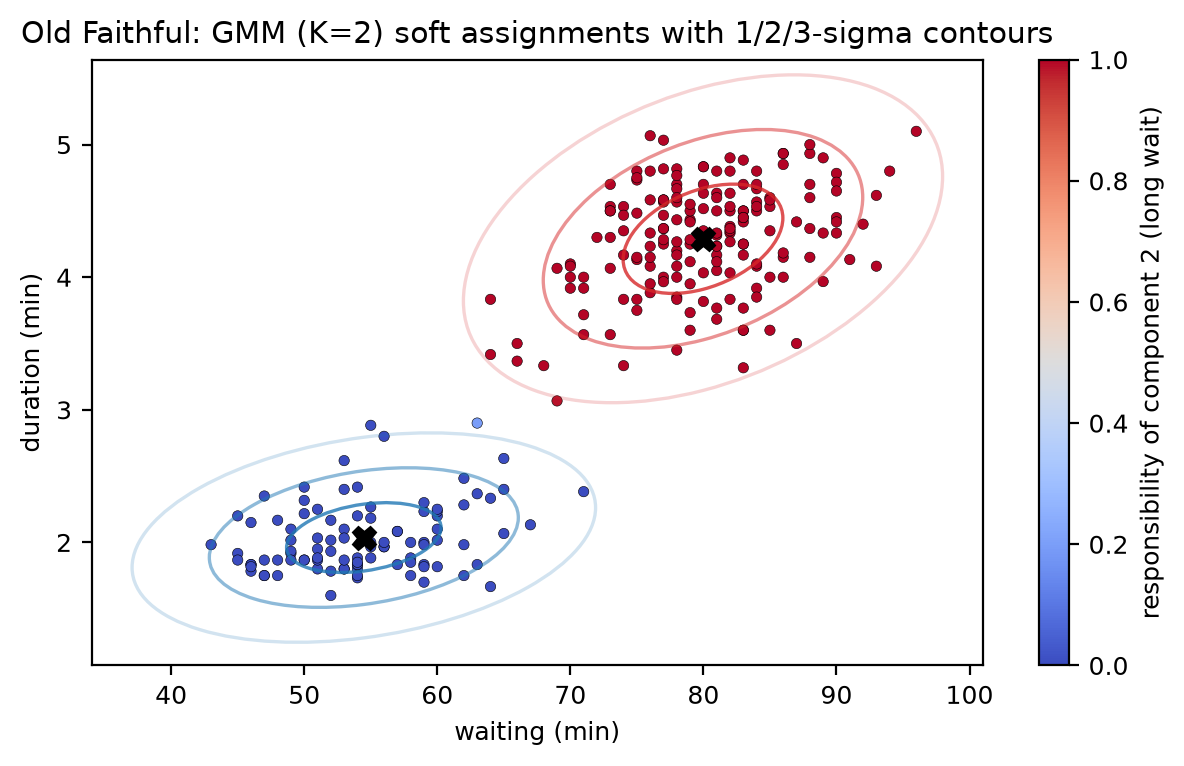

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 3.9))
sc = ax.scatter(X2[:, 0], X2[:, 1], c=resp[:, order[1]], cmap="coolwarm", s=14, edgecolor="k", lw=0.2)
for idx, color in zip(order, ("tab:blue", "tab:red")):
    draw_ellipses(ax, gmm.means_[idx], gmm.covariances_[idx], color)
    ax.plot(*gmm.means_[idx], marker="X", color="k", ms=8)
fig.colorbar(sc, ax=ax, label="responsibility of component 2 (long wait)")
ax.set_xlabel("waiting (min)")
ax.set_ylabel("duration (min)")
ax.set_title("Old Faithful: GMM (K=2) soft assignments with 1/2/3-sigma contours")
fig.tight_layout()
plt.show()

## Complete numeric results for reproducibility

In [7]:
print(json.dumps(results["task2"], sort_keys=True))

{"converged": true, "covariances": [[[33.704933521773434, 0.4362772308942487], [0.43627723089424864, 0.06927448767682572]], [[36.02497018823675, 0.9387179338088993], [0.9387179338088993, 0.16982045993720735]]], "means": [[54.47986017773616, 2.036521489193544], [79.96953297889249, 4.289779435727314]], "n_iter": 4, "n_samples": 272, "weights": [0.3559274466226758, 0.6440725533773242]}
